In [1]:
#!pip3 install torch_geometric
import locale
locale.getpreferredencoding = lambda: "UTF-8"

#!pip3 install -U "huggingface_hub[cli]"

In [2]:


#LOGIN TO HUGGINGFACE TO USE LLAMA
#!huggingface-cli login
#from huggingface_hub import notebook_login

#notebook_login()

In [3]:
#%pip install torch matplotlib rpy2 wandb scipy pandas numpy networkx torch_geometric transformers

In [4]:
#import sys
#sys.path.append('/content/drive/MyDrive')

import torch
import sys
import pandas as pd
import numpy as np
import networkx as nx

print(f'torch=={torch.__version__}')
print(f'pandas=={pd.__version__}')
print(f'numpy=={np.__version__}')
print(f'networkx=={nx.__version__}')

import tqdm
import matplotlib.pyplot as plt
from itertools import chain

sys.path.append('.')
from agfn.gflownet import GFlowNet
from agfn.gym import MAG, LogReward
from agfn.models import ForwardPolicy, BackwardPolicy

torch==2.5.1+cu124
pandas==2.2.3
numpy==2.2.2
networkx==3.4.2


In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [6]:
torch.set_default_dtype(torch.float64)

In [7]:
#data = pd.read_csv('drive/MyDrive/agfn/1000.csv')
data = pd.read_csv('sachs.csv')
#data = pd.read_csv('sachs_7vars.csv')
#data = pd.read_csv('sachs_5vars.csv')

node_labels = data.columns.tolist()
data = torch.tensor(data.values, device=device, dtype=torch.get_default_dtype())
num_nodes = data.shape[1]
print(f'Number of variables: {num_nodes}')

Number of variables: 11


In [8]:
pf = ForwardPolicy(num_nodes, num_layers=2, hidden_dim=256, device=device)
pb = BackwardPolicy(device)
gflownet = GFlowNet(pf, pb, criterion='tb', device=device)

In [9]:
create_env = lambda batch_size=64: MAG(num_nodes, batch_size, log_reward, device=device)

In [10]:
log_reward = LogReward(dataset=data, device=device)
log_reward.warmup(gflownet, create_env, 32)

In [11]:
def train(gflownet, create_env, epochs, lr=1e-3, lr_logz=1e-1, use_scheduler=False):
    optimizer = torch.optim.Adam([
        {'params': chain(gflownet.pf.parameters(), gflownet.pb.parameters()), 'lr': lr},
        {'params': gflownet.log_z, 'lr': lr_logz}])
    scheduler = torch.optim.lr_scheduler.PolynomialLR(optimizer, total_iters=epochs)

    losses = list()
    pbar = tqdm.tqdm(range(epochs), disable=False)
    for epoch in pbar:
        optimizer.zero_grad()
        env = create_env()
        loss = gflownet(env)
        loss.backward()
        optimizer.step()
        pbar.set_postfix(loss=loss.item())
        # Update the exploration rate
        losses.append(loss.item())
        if use_scheduler:
            scheduler.step()
    return losses


100%|█████████████████████████████████████████████████████████████████████████████████████| 1024/1024 [08:59<00:00,  1.90it/s, loss=18.3]


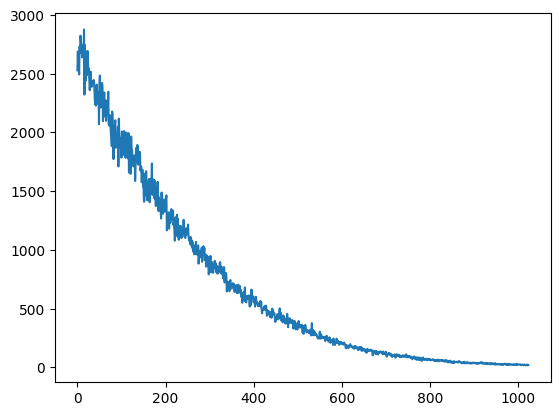

In [12]:
losses = train(gflownet, create_env, epochs=int(1024))
plt.plot(losses)

In [13]:
gflownet.eval()
env = create_env()
env = gflownet.sample(env)

In [14]:
pag_no_llm = MAG.mag_to_pcalg(env.adjacency_matrix)
pag_no_llm = pag_no_llm.cpu()

In [15]:
#RUN THIS TO SAVE MAG WITHOUT LITL (LLM IN THE LOOP)

#for idx, tensor in enumerate(pag_no_llm):
    #pd.DataFrame(tensor.numpy()).to_csv(f'pag_no_llm_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'7pag_no_llm_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'5pag_no_llm_{idx}.csv', index=None)

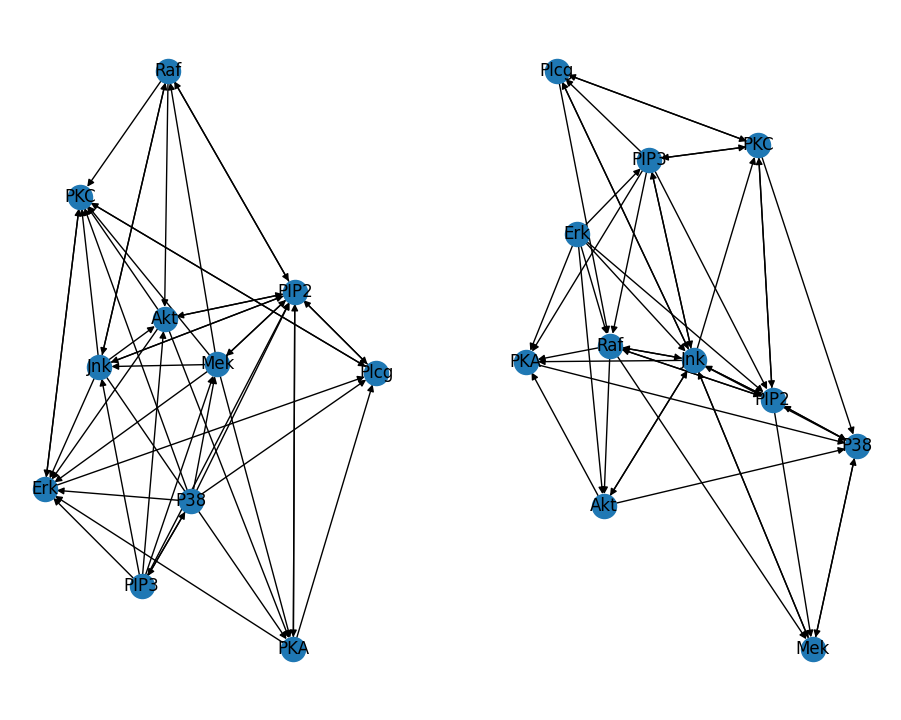

In [16]:
plt.figure(figsize=(30, 20))
indices = torch.topk(env.log_reward(), k=2).indices
for e, i in enumerate(indices):
    plt.subplot(2, 5, e + 1)
    env.draw(i, labels=node_labels)

## LLM-in-the-loop pipeline  

We provide below an example of how to use the principled HITL pipeline of our work or a pragmatic, probably more useful, instantiation of it.

The original code was heavily tailored to the estimation of functionals and not so much for sampling.

We recall that a graph of $n$ nodes is represented by a matrix $\mathbf{A} = \{1, 0\}^{{n \choose 2} \times 4}$. Each row of $\mathbf{A}$ is an indicator function representing the direction of the edge.

In particular, for each $i < j$, $A_{ij} = (1, 0, 0, 0)$ represents an inexisting edge; $A_{ij} = (0, 1, 0, 0)$ represents an edge from $i$ to $j$, etc. Please refer to `hitl.EdgeType`.

The expert feedback is represented as a probability vector $\mathbf{p} \in \{1, 0\}^{d}$ denoting the expert's confidence on each relationship.  

In [17]:
#1) not related
#2) A->B
#3) B->A
#4) A<->B

#ask the llm only the queried edge

#import llm_prompting.utils
import math
from transformers import pipeline
import statistics
from statistics import mode

def call_llama3(prompt):
    messages = [
        {"role": "system", "content": "You are a chatbot who always responds in numbers"},
        {"role": "user", "content": prompt}
    ]

    input_ids = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    terminators = [
        tokenizer.eos_token_id,
        tokenizer.convert_tokens_to_ids("<|eot_id|>")
    ]
    
    possible_result = []
    p = 1
    print(prompt)
    for i in range(10):
        outputs = model.generate(
            input_ids,
            max_new_tokens=256,
            eos_token_id=terminators,
            do_sample=True,
            temperature=0.6,
            top_p=0.9,
        )
        response = outputs[0][input_ids.shape[-1]:]
        possible_result.append(int(tokenizer.decode(response, skip_special_tokens=True)))
    #if there's a tie, mode chooses first element
    result = mode(possible_result)
    p = possible_result.count(result)/10
    print(result, p)
    return result, p


def call_llm(vars, llm):
    prompt = 'According to scientists, what is the causal relation between {v1} and {v2}? Your answer must be only one number. Answer "0" if they are not related, answer "1" if {v1} causes {v2}, answer "2" if {v2} causes {v1} and answer "3" if they have common ancestor(s).'.format(v1=vars[0], v2=vars[1])

    #for chatgpt:
    if llm == "chatgpt":
        print(prompt)
        possible_result = []
        p = 1
        for i in range(10):        
            possible_result.append(int(input('\nchatgpt answer {}:'.format(i))))
        #if there's a tie, mode chooses first element
        result = mode(possible_result)
        p = possible_result.count(result)/10


    if llm == "llama3":
        result,p = call_llama3(prompt)

    return result, p

def get_llm_feedback(query, node_list, llm):
    num_nodes = len(node_list)
    max_edges = int(math.factorial(num_nodes)/(2*math.factorial(num_nodes-2)))
    print(max_edges)
    llm_graph = torch.zeros((max_edges, 4), dtype=torch.long, device=device)

    if (llm_graph[query]==0).all():
        sum = 0
        for i in range(num_nodes):
            sum += i+1
            if query < (i+1)*num_nodes-sum:
                vars = [node_list[i],node_list[-(((i+1)*num_nodes-sum)-query)]]
                break
    else:
        return llm_graph[query]

    #call_llm returns a number from 0 to 3 representing the edge that relates (A,B)
    #acording to hitl.EdgeType
    result, p = call_llm(vars, llm)
    llm_graph[query][result] = 1

    return llm_graph[query], p



In [18]:
#%pip install airllm sentencepiece

In [19]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline

#tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")
#model = AutoModelForCausalLM.from_pretrained("meta-llama/Llama-3.1-8B-Instruct").to("cuda")

#base_model_id = "meta-llama/Llama-3.3-70B-Instruct"
base_model_id = "meta-llama/Llama-3.1-8B-Instruct"
#base_model_id = "meta-llama/Llama-3.3-70B-Instruct"
#base_model_id = "allenai/OLMo-2-1124-13B-Instruct"


tokenizer = AutoTokenizer.from_pretrained(base_model_id)
model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    torch_dtype=torch.bfloat16,
    #quantization_config=gptq_config,
    #device_map="auto",
).to("cuda")

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 112.00 MiB. GPU 0 has a total capacity of 23.68 GiB of which 98.81 MiB is free. Including non-PyTorch memory, this process has 14.34 GiB memory in use. Process 3030294 has 736.00 MiB memory in use. Process 3030319 has 736.00 MiB memory in use. Process 3030378 has 736.00 MiB memory in use. Process 3030393 has 736.00 MiB memory in use. Process 3030413 has 736.00 MiB memory in use. Process 3030417 has 736.00 MiB memory in use. Process 3030479 has 736.00 MiB memory in use. Process 3030515 has 736.00 MiB memory in use. Process 3031019 has 736.00 MiB memory in use. Process 3031020 has 736.00 MiB memory in use. Process 3031028 has 736.00 MiB memory in use. Process 3031029 has 736.00 MiB memory in use. Of the allocated memory 13.89 GiB is allocated by PyTorch, and 143.73 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentatio

In [ ]:
#the expert already has the matrix entirely complete, the system queries on specific
#edges a determined amount of times

#def get_expert_feedback(query):
#    true_graph = torch.tensor([
#        [0, 1, 0, 0], # (A, B)
#        [1, 0, 0, 0], # (A, C)
#        [1, 0, 0, 0], # (A, D)
#        [0, 1, 0, 0], # (B, C)
#        [1, 0, 0, 0], # (B, D)
#        [0, 1, 0, 0], # (C, D)
#    ], device=device)
#    return true_graph[query] # The expert is an oracle

#pi = .99 # our confidence on the expert


Calculate the model-based prior and declare the (currently empty) list of feedbacks and queries.

In [ ]:
## Sample a batch of graphs
from agfn.hitl import sample_massive_batch, nquery, sample_from_expert, edge_marks_to_adj, fpost

In [ ]:
gflownet.eval()
graphs, log_rewards = sample_massive_batch(gflownet, create_env, num_batches=128)

The prior distribution is a matrix $\mathbf{P} \in \mathbb{R}^{{n \choose 2} \times 4}$ in which each row represents a probability distribution over the each relationship.

In [ ]:
priors = graphs.edge_marks.float().mean(dim=0)

In [ ]:
num_hitl_rounds = 10 # Maximum number of feedbacks (<= maximum number of edges)


In [ ]:
feedbacks = torch.zeros((0,), dtype=torch.long, device=device) # list of 0-3 integers representing the feedback
queries = torch.zeros((0,), dtype=torch.long, device=device) # list of edge indexes corresponding to the feedback

pi=1
for round in range(num_hitl_rounds):
    # Elicit a novel query
    query = nquery(
        graphs.edge_marks, log_rewards, feedbacks, priors, queries, pi
    )
    print(query)

    # Sample from the expert's distribution
    #expert_confidence, pi = get_llm_feedback(query,node_labels, "chatgpt")
    expert_confidence, pi = get_llm_feedback(query,node_labels, "llama3")
    #print(expert_confidence, pi)
    fprob = pi * expert_confidence + (1 - expert_confidence) * (1 - pi) / 3
    fdist = torch.distributions.Categorical(fprob)
    fdbck = fdist.sample(sample_shape=(1,))
    # We could also take a MAP estimate
    # fdbck = fprob.argmax()

    # Update the list of feedbacks
    queries = torch.hstack([queries, query])
    feedbacks = torch.hstack([feedbacks, fdbck])

In [ ]:
pi = 1
expert_graphs, expert_log_rewards, _ = \
    sample_from_expert(feedbacks, queries, priors, 512, 128, gflownet, pi, data, log_reward)

In [ ]:
expert_amat = edge_marks_to_adj(expert_graphs).long()

In [ ]:
#EXPERT DISTRIBUTION
plt.figure()
#plt.figure(figsize=(24, 10))
env = create_env()
for e, i in enumerate(indices):
    plt.subplot(2, 5, e + 1)
    env.draw(i, labels=node_labels, amat=expert_amat[i].cpu().numpy())

In [ ]:
#GFlowNet weighted by the expert's model

In [ ]:
gflownet.eval()
graphs, log_rewards = sample_massive_batch(gflownet, create_env, num_batches=128)

In [ ]:
expert_weights = fpost(
    graphs.edge_marks, feedbacks, priors, queries, pi
).mean(dim=1)

env = create_env()
env = gflownet.sample(env)
pag_llm = MAG.mag_to_pcalg(env.adjacency_matrix)

In [ ]:
plt.figure(figsize=(24, 10))
indices = torch.topk(expert_weights, k=10).indices
for e, i in enumerate(indices):
    plt.subplot(2, 5, e + 1)
    graphs.draw(i, labels=node_labels)

In [ ]:
#torch.save(pag_llm, "pag_llm.csv")
#torch.save(pag_no_llm, "pag_no_llm.csv")

In [ ]:
pag_llm = pag_llm.cpu()
for idx, tensor in enumerate(pag_llm):
    #pd.DataFrame(tensor.numpy()).to_csv(f'pag_llm_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'7pag_llm_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'5pag_llm_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'5pag_llama3_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'7pag_llama3_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'pag_llama3_{idx}.csv', index=None)